# Dataset

Explorar el dataset

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

## Rutas

In [2]:
CWD = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (CWD, *CWD.parents) if (path / "pyproject.toml").is_file()
)

In [3]:
DATA_DIR = PROJECT_ROOT / "data"
TRAIN_PATH = DATA_DIR / "training.h5"
VALIDATION_PATH = DATA_DIR / "validation.h5"

In [4]:
print(TRAIN_PATH)
print(VALIDATION_PATH)

/Users/hugo.angeles/Code/utec-deeplearning-lab03/data/training.h5
/Users/hugo.angeles/Code/utec-deeplearning-lab03/data/validation.h5


In [5]:
def show_data(name, content):
    if isinstance(content, h5py.Dataset):
        print(f"{name}: shape={content.shape}, dtype={content.dtype}")
    else:
        print(f"{name}/")


# Training data
with h5py.File(TRAIN_PATH, "r") as file:
    print("Atributos del archivo:", dict(file.attrs))
    file.visititems(show_data)
    print()

# Validation data
with h5py.File(VALIDATION_PATH, "r") as file:
    print("Atributos del archivo:", dict(file.attrs))
    file.visititems(show_data)
    print()

Atributos del archivo: {'color_space': 'RGB', 'complete': np.True_, 'final_training': 'After choosing the configuration, combine these images with validation/query/images and validation/gallery/images, without using identity labels.', 'layout': 'NCHW', 'pixel_range': '0-255', 'source': 'Market-1501-v15.09.15', 'source_readme': '%******************************************************************************************************************%\n% The Market-1501 dataset is collected with six cameras, open environment, in Tsinghua University.                 %\n% A total of 1501 individuals are annotated. 751 individuals are used for training. There are 750 individuals for  % \n% testing, and in total 3368 query images.                                                                         %\n% There are 19732 images in the test set, and 12936 images in the training set.                                    %\n% If you use this dataset, please kindly cite our paper as,                    

In [6]:
print("Formato NCHW: (imágenes, canales, alto, ancho)\n")

for split, path, keys in (
    ("training", TRAIN_PATH, ["images"]),
    (
        "validation",
        VALIDATION_PATH,
        ["gallery/images", "query/images", "query/images_low_resolution"],
    ),
):
    with h5py.File(path, "r") as file:
        for key in keys:
            images = file[key]
            n, c, h, w = images.shape
            print(f"{split}/{key}: {images.shape}, {images.dtype}")
            print(f"  {n:,} imágenes RGB de {h} × {w} píxeles ({c} canales)")

Formato NCHW: (imágenes, canales, alto, ancho)

training/images: (11043, 3, 128, 64), uint8
  11,043 imágenes RGB de 128 × 64 píxeles (3 canales)
validation/gallery/images: (1793, 3, 128, 64), uint8
  1,793 imágenes RGB de 128 × 64 píxeles (3 canales)
validation/query/images: (100, 3, 128, 64), uint8
  100 imágenes RGB de 128 × 64 píxeles (3 canales)
validation/query/images_low_resolution: (100, 3, 32, 16), uint8
  100 imágenes RGB de 32 × 16 píxeles (3 canales)


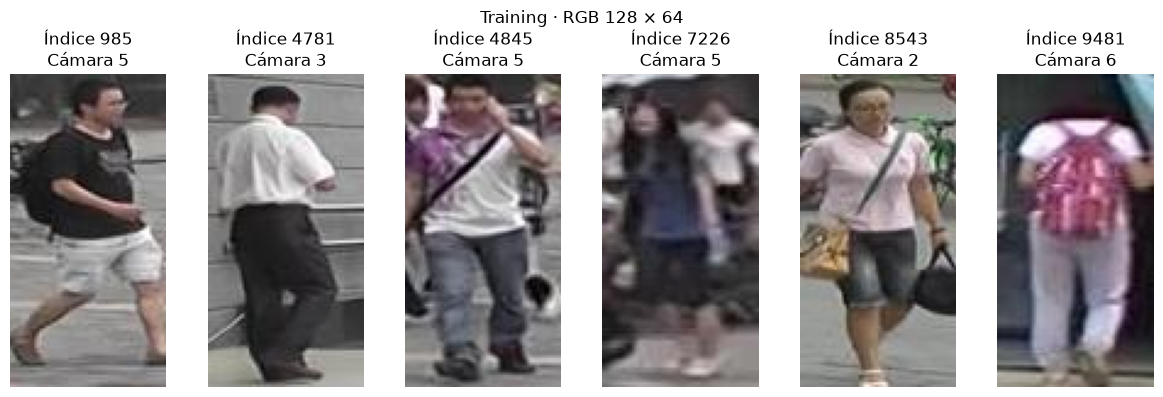

In [7]:
rng = np.random.default_rng(42)

with h5py.File(TRAIN_PATH, "r") as file:
    indices = np.sort(rng.choice(len(file["images"]), size=6, replace=False))
    sample_images = file["images"][indices]
    sample_cameras = file["camera_ids"][indices]

fig, axes = plt.subplots(1, 6, figsize=(12, 4))
for ax, image, index, camera in zip(
    axes, sample_images, indices, sample_cameras, strict=True
):
    ax.imshow(image.transpose(1, 2, 0))
    ax.set_title(f"Índice {index}\nCámara {camera}")
    ax.axis("off")

fig.suptitle("Training · RGB 128 × 64")
plt.tight_layout()
plt.show()

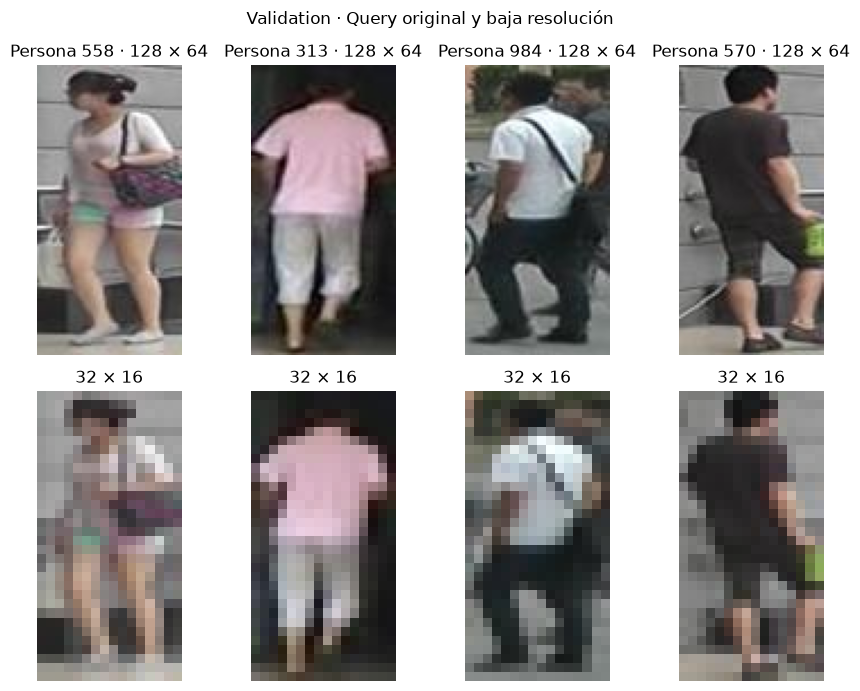

In [8]:
with h5py.File(VALIDATION_PATH, "r") as file:
    query = file["query"]
    indices = np.sort(rng.choice(len(query["images"]), size=4, replace=False))
    query_images = query["images"][indices]
    query_low_resolution = query["images_low_resolution"][indices]
    person_ids = query["person_ids"][indices]

fig, axes = plt.subplots(2, 4, figsize=(9, 7))
for column, (image, low_resolution, person_id) in enumerate(
    zip(query_images, query_low_resolution, person_ids, strict=True)
):
    axes[0, column].imshow(image.transpose(1, 2, 0))
    axes[0, column].set_title(f"Persona {person_id} · 128 × 64")
    axes[1, column].imshow(low_resolution.transpose(1, 2, 0), interpolation="nearest")
    axes[1, column].set_title("32 × 16")

for ax in axes.flat:
    ax.axis("off")

fig.suptitle("Validation · Query original y baja resolución")
plt.tight_layout()
plt.show()